# Final Project 2: Data integration and PCA of DC census tracts

**Team:** Myles Lewis, Kiet Ly  |  **Course:** CDS 303 (Data Mining)

**Goal.** Principal components analysis will be used to reduce dimensionality for the DC census tracts, based on timing of crime, number of alcohol establishments and number of Metro entries. Principal components do not identify clusters. Clustering and classification will occur at a later stage.


**Input.** `data/dc_tract_table_2025.xlsx`, the output of our spatial-join notebook: one row per 2020 census tract (206 tracts)
combining 2025 crime incidents, alcohol licenses, Metro station entrances and ACS 2020-2024 demographics.
See `data/README.md` for sources and how every file was produced.


## 1. Settings and imports

In [ ]:
import os, zipfile
from pathlib import Path
# Only needed in Google Colab, where the project folder is not there yet. Skipped when the repository is cloned or the notebook is run locally.
if not Path('data/dc_tract_table_2025.xlsx').exists():
    from google.colab import files
    uploaded = files.upload()            # choose DC_Crime_PCA_Project.zip
    zipfile.ZipFile(next(iter(uploaded))).extractall('.')
    os.chdir('final_project2')

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path
from sklearn.decomposition import PCA

# ---- Settings (change here, then Restart & Run All) -------------------------------------------
RANDOM_SEED    = 42      # only used for the parallel-analysis permutations
MIN_TIMING_N   = 30      # a tract needs >= 30 incidents (reported within 1 day) behind its timing shares
N_PERMUTATIONS = 1000    # permutations for parallel analysis
DATA_FILE = Path('data/dc_tract_table_2025.xlsx')
FIG_DIR, OUT_DIR = Path('figures'), Path('outputs')
FIG_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)

pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', 80)

# ---- Chart style (recessive grid, thin marks) ----------------------------------------------------
INK, INK2, MUTED, GRID, AXIS, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#fcfcfb'
BLUE, ORANGE, RED, NEUTRAL = '#2a78d6', '#eb6834', '#e34948', '#f0efec'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
                     'axes.facecolor': SURFACE, 'savefig.dpi': 150})
def style_axes(ax, grid='both'):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    for s in ('left', 'bottom'): ax.spines[s].set_color(AXIS)
    ax.grid(True, axis=grid, color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.xaxis.label.set_color(INK2); ax.yaxis.label.set_color(INK2); ax.title.set_color(INK)

## 2. Load the integrated table and check the merge

Each row is **one 2020 census tract** (key: 11-digit `GEOID` = `11001` + 6-digit tract code). The merges were done in the
spatial-join notebook: crime points, alcohol-license points and Metro-entrance points were each assigned to a tract polygon,
counted per tract, and joined to the polygon table by `GEOID`; ACS tract data were joined by `GEOID` as well.
The checks below confirm that no tract was duplicated or lost and that the totals carried through.

In [ ]:
tracts = pd.read_excel(DATA_FILE, dtype={'GEOID': str, 'TRACT': str})
offense_cols = ['arson_n', 'assault_n', 'burglary_n', 'homicide_n', 'mv_theft_n', 'robbery_n', 'sexabuse_n', 'theftcar_n', 'theftoth_n']

# --- one row per tract, no duplicates, valid DC tract codes
assert len(tracts) == 206 and tracts['GEOID'].is_unique
assert tracts['GEOID'].str.len().eq(11).all() and tracts['GEOID'].str.startswith('11001').all()
# --- totals carried through the merges
assert tracts['crime_n'].sum() == tracts[offense_cols].sum().sum()          # offense counts add up to the total
assert tracts['population'].sum() == 681_294                                 # equals the DC total in the Social Explorer ACS export
print(f"rows: {len(tracts)} | unique GEOIDs: {tracts['GEOID'].nunique()}")
print(f"crime records inside a tract : {tracts['crime_n'].sum():,}   (23,937 cleaned incidents; 101 fall ~1-3 m outside a polygon edge, see report)")
print(f"alcohol licenses kept        : {tracts['alc_total_n'].sum():,}")
print(f"Metro entrances              : {tracts['metro_entrance_n'].sum():,}")
print(f"ACS population, sum of tracts: {tracts['population'].sum():,}")

# --- geography check: ACS 2020-2024 and the 2020 census polygons should describe the same tracts
r = tracts['population'].corr(tracts['POP100'])
med_gap = ((tracts['population'] - tracts['POP100']).abs() / tracts['POP100']).median()
print(f"\nACS population vs 2020 census population (POP100): r = {r:.3f}, median absolute gap = {med_gap:.1%}")
tracts[['GEOID', 'NAME', 'POP100', 'population', 'crime_n', 'timing_n', 'alc_total_n', 'metro_entrance_n']].head()

rows: 206 | unique GEOIDs: 206
crime records inside a tract : 23,836   (23,937 cleaned incidents; 101 fall ~1-3 m outside a polygon edge, see report)
alcohol licenses kept        : 2,075
Metro entrances              : 113
ACS population, sum of tracts: 681,294

ACS population vs 2020 census population (POP100): r = 0.922, median absolute gap = 7.5%


,GEOID,NAME,POP100,population,crime_n,timing_n,alc_total_n,metro_entrance_n
0,11001002002,Census Tract 20.02,4072,4019,85,60,2,0
1,11001002101,Census Tract 21.01,5687,5453,173,120,20,0
2,11001002102,Census Tract 21.02,5099,5702,102,78,7,0
3,11001002201,Census Tract 22.01,3485,3502,54,39,5,0
4,11001002202,Census Tract 22.02,3339,3169,76,60,3,0


**Units and time periods being combined.** All five sources are brought to the *tract* level before they meet, so no row is
duplicated. The time periods differ, which is a limitation to keep in mind:

| Source | Unit before merge | Period | How it enters the table |
|---|---|---|---|
| DC crime incidents (MPD) | point (block-level location) | calendar year 2025 | counted and averaged per tract after a spatial join |
| Alcohol licenses (ABCA) | point | snapshot created May 2026 | counted per tract after a spatial join |
| Metro station entrances (WMATA) | point | locations captured 2016 | counted per tract after a spatial join |
| ACS 5-year estimates (Census Bureau) | census tract | 2020-2024 | joined on `GEOID` (context only) |
| Census tract polygons (DC GIS) | polygon | 2020 boundaries | defines the unit of analysis |

## 3. Choose and build the PCA variables

**Timing variables (from the crime data).** `share_daytime`, `share_evening` and `share_midnight` **sum to 1**, so one is
redundant: knowing two determines the third. Keeping all three makes the correlation matrix singular. We drop `share_daytime` as the
reference category, which loses no information. `share_weekend` is kept.

**Nightlife / transit densities (from the supplementary data).** Counts are converted to **density per km² of land**
(`ALAND` is land area in m²) so a large tract is not favored simply for being large; per-resident rates are unstable where very few
people live. We use `alc_total`, `bar_club`, `dancing` and `metro_entrance`. `entertain` is dropped because it is about 0.95
correlated with total license density. Densities are then log-transformed with `log1p`.

**Not PCA inputs:** identifiers (`GEOID`, `TRACT`, `NAME`); tract volume (`crime_n`, `timing_n`, used only to filter tracts, so the PCA
reflects *timing*, not how much crime a tract has); raw counts (they track tract size); `share_violent`, `share_gun` and the offense
counts (reserved as classification predictors); and the ACS variables (context for interpretation). No categorical variable is
used, so nothing is encoded.

In [ ]:
t = tracts.copy()
t['land_km2'] = t['ALAND'] / 1e6
for c in ['alc_total', 'bar_club', 'dancing', 'entertain', 'metro_entrance']:
    t[f'{c}_per_km2'] = t[f'{c}_n'] / t['land_km2']
t['log_alc_total_per_km2']       = np.log1p(t['alc_total_per_km2'])
t['log_bar_club_per_km2']        = np.log1p(t['bar_club_per_km2'])
t['log_dancing_per_km2']         = np.log1p(t['dancing_per_km2'])
t['log_metro_entrance_per_km2']  = np.log1p(t['metro_entrance_per_km2'])

# name -> (group, plain-language definition)
FEATURES = {
    'share_evening':              ('Timing',              'Share of incidents starting 15:00-22:59 (Eastern)'),
    'share_midnight':             ('Timing',              'Share of incidents starting 23:00-06:59'),
    'share_weekend':              ('Timing',              'Share of incidents starting on Saturday/Sunday'),
    'log_alc_total_per_km2':      ('Alcohol and transit', 'ln(1 + all alcohol licenses per km2 of land)'),
    'log_bar_club_per_km2':       ('Alcohol and transit', 'ln(1 + taverns and nightclubs per km2)'),
    'log_dancing_per_km2':        ('Alcohol and transit', 'ln(1 + licenses that allow dancing per km2)'),
    'log_metro_entrance_per_km2': ('Alcohol and transit', 'ln(1 + Metro station entrances per km2)'),
}
FEATURES_LIST = list(FEATURES)
LABELS = {'share_evening': 'Evening share', 'share_midnight': 'Midnight share', 'share_weekend': 'Weekend share',
          'log_alc_total_per_km2': 'All licenses per km2 (log)', 'log_bar_club_per_km2': 'Bars and nightclubs per km2 (log)',
          'log_dancing_per_km2': 'Dancing licenses per km2 (log)', 'log_metro_entrance_per_km2': 'Metro entrances per km2 (log)'}
pd.DataFrame([(k, g, d) for k, (g, d) in FEATURES.items()], columns=['variable', 'group', 'definition'])

,variable,group,definition
0,share_evening,Timing,Share of incidents starting 15:00-22:59 (Eastern)
1,share_midnight,Timing,Share of incidents starting 23:00-06:59
2,share_weekend,Timing,Share of incidents starting on Saturday/Sunday
3,log_alc_total_per_km2,Alcohol and transit,ln(1 + all alcohol licenses per km2 of land)
4,log_bar_club_per_km2,Alcohol and transit,ln(1 + taverns and nightclubs per km2)
5,log_dancing_per_km2,Alcohol and transit,ln(1 + licenses that allow dancing per km2)
6,log_metro_entrance_per_km2,Alcohol and transit,ln(1 + Metro station entrances per km2)


## 4. Choose which tracts to analyze, and handle missing values

In [ ]:
print('Sensitivity of the cutoff (tracts kept / excluded):')
for m in (20, 30, 50):
    print(f'  timing_n >= {m}: {int((t.timing_n >= m).sum())} kept, {int((t.timing_n < m).sum())} excluded')

keep = t['timing_n'] >= MIN_TIMING_N
t['status'] = np.where(keep, 'kept', f'fewer than {MIN_TIMING_N} reliably timed incidents')
t.loc[~keep, ['GEOID', 'NAME', 'crime_n', 'timing_n', 'POP100']].to_csv(OUT_DIR / 'pca_excluded_tracts.csv', index=False)

analysis = t.loc[keep, ['GEOID', 'NAME'] + FEATURES_LIST].reset_index(drop=True)
print(f'\nEligible tracts (timing_n >= {MIN_TIMING_N}): {len(analysis)}; excluded: {int((~keep).sum())}')
print('Missing values in PCA variables:', int(analysis[FEATURES_LIST].isna().sum().sum()))
assert analysis[FEATURES_LIST].notna().all().all()
print('Tracts per variable:', round(len(analysis) / len(FEATURES_LIST), 1))

Sensitivity of the cutoff (tracts kept / excluded):
  timing_n >= 20: 184 kept, 22 excluded
  timing_n >= 30: 174 kept, 32 excluded
  timing_n >= 50: 132 kept, 74 excluded

Eligible tracts (timing_n >= 30): 174; excluded: 32
Missing values in PCA variables: 0
Tracts per variable: 24.9


**Why this filter.** A tract's timing shares come only from incidents reported within a day of starting. With a handful of
incidents, a share such as "midnight" is mostly sampling noise, so we require at least 30 (section 10 checks 20 and 50).
The PCA variables have **no missing values** (a tract with no bars has a true count of 0), so nothing is imputed.
The ACS context variables do have a few missing values (income, median age, renter share). They are context, not PCA
inputs, so no imputation is needed.

## 5. Check skewness and redundancy

In [ ]:
dens_raw = {'log_alc_total_per_km2': 'alc_total_per_km2', 'log_bar_club_per_km2': 'bar_club_per_km2',
            'log_dancing_per_km2': 'dancing_per_km2', 'log_metro_entrance_per_km2': 'metro_entrance_per_km2'}
sk = pd.DataFrame({'raw density': {v: t.loc[keep, raw].skew() for v, raw in dens_raw.items()},
                   'after log1p': {v: t.loc[keep, v].skew() for v in dens_raw}}).round(2)
print('Skewness (values near 0 are symmetric; > 1 is strongly right-skewed):'); print(sk.to_string())
print('\nTime shares (they sum to 1, so share_daytime is dropped):')
print(t.loc[keep, ['share_daytime', 'share_evening', 'share_midnight']].corr().round(2).to_string())
print('\nRedundancy: correlation of total vs entertainment license density =',
      round(t.loc[keep, 'alc_total_per_km2'].corr(t.loc[keep, 'entertain_per_km2']), 2), '(so entertain is dropped)')

c = analysis[FEATURES_LIST].corr()
top = c.where(np.triu(np.ones(c.shape, bool), 1)).stack().abs().sort_values(ascending=False).head(5)
print('\nStrongest correlations among the final variables:'); print(c.stack().loc[top.index].round(2).to_string())

Skewness (values near 0 are symmetric; > 1 is strongly right-skewed):
                            raw density  after log1p
log_alc_total_per_km2              2.29         0.18
log_bar_club_per_km2               4.19         0.77
log_dancing_per_km2                3.85         1.21
log_metro_entrance_per_km2         2.89         1.83

Time shares (they sum to 1, so share_daytime is dropped):
                share_daytime  share_evening  share_midnight
share_daytime            1.00          -0.48           -0.62
share_evening           -0.48           1.00           -0.40
share_midnight          -0.62          -0.40            1.00

Redundancy: correlation of total vs entertainment license density = 0.95 (so entertain is dropped)

Strongest correlations among the final variables:
log_alc_total_per_km2  log_bar_club_per_km2          0.87
log_bar_club_per_km2   log_dancing_per_km2           0.80
log_alc_total_per_km2  log_dancing_per_km2           0.78
share_evening          share_midnight

## 6. Standardize

Shares are on a 0-1 scale and the log densities are in different units. PCA maximizes variance, so without standardizing, the
variable with the largest raw variance would dominate. Each variable is converted to a z-score (mean 0, standard deviation 1), so
PCA is done on the **correlation matrix**. The standard deviation uses `ddof=1` so that the PCA eigenvalues equal those of the
correlation matrix exactly. (This matches `StandardScaler` up to a constant factor; the loadings and the component choice
are unchanged.) Standardizing also inflates small, noisy shares, which is one reason for the minimum-incident filter.

In [ ]:
X = analysis[FEATURES_LIST]
Z = (X - X.mean()) / X.std(ddof=1)
print('max |mean| of z-scores:', round(float(Z.mean().abs().max()), 12), '| all standard deviations equal 1:', bool(np.allclose(Z.std(ddof=1), 1)))

# Outlier check: any tract more than 3.5 standard deviations from a variable's mean
out = Z.abs().stack(); out = out[out > 3.5]
outliers = pd.DataFrame({'tract': analysis.loc[out.index.get_level_values(0), 'NAME'].values,
                         'variable': out.index.get_level_values(1), 'z': Z.stack().loc[out.index].round(2).values})
print('\nValues beyond 3.5 standard deviations (kept in the PCA; flagged for the report):'); print(outliers.to_string(index=False) if len(outliers) else 'none')
outlier_geoids = analysis.loc[out.index.get_level_values(0).unique(), 'GEOID'].tolist()    # used in the sensitivity checks
print('Tracts with at least one such value:', len(outlier_geoids))

max |mean| of z-scores: 0.0 | all standard deviations equal 1: True

Values beyond 3.5 standard deviations (kept in the PCA; flagged for the report):
          tract      variable     z
Census Tract 15 share_weekend -3.54
Tracts with at least one such value: 1


## 7. Apply PCA and choose the number of components

In [ ]:
pca = PCA(svd_solver='full').fit(Z)
eig = pca.explained_variance_                         # eigenvalues of the correlation matrix
assert np.isclose(eig.sum(), len(FEATURES_LIST))       # eigenvalues of a correlation matrix sum to the number of variables

# PC signs are arbitrary; flip each component so its largest-magnitude loading is positive (makes results reproducible)
comps = pca.components_.copy()
for i in range(len(comps)):
    if comps[i, np.argmax(np.abs(comps[i]))] < 0: comps[i] *= -1
scores   = Z.values @ comps.T                          # tract scores on every PC
loadings = comps.T * np.sqrt(eig)                      # loading = correlation between a variable and a PC
assert np.isclose(np.corrcoef(Z.values[:, 0], scores[:, 0])[0, 1], loadings[0, 0])

# Parallel analysis: eigenvalues expected from data with the same size but no structure (each column shuffled independently)
rng = np.random.default_rng(RANDOM_SEED)
n, p = Z.shape
sim = np.empty((N_PERMUTATIONS, p))
for i in range(N_PERMUTATIONS):
    shuffled = np.column_stack([rng.permutation(Z.values[:, j]) for j in range(p)])
    sim[i] = np.linalg.eigvalsh(np.corrcoef(shuffled, rowvar=False))[::-1]
pa95 = np.percentile(sim, 95, axis=0)

beats_chance = eig > pa95
n_keep = int(np.argmin(beats_chance)) if not beats_chance.all() else p       # leading components that beat chance

ev = pd.DataFrame({'PC': [f'PC{i + 1}' for i in range(p)], 'eigenvalue': eig, 'explained_variance_ratio': pca.explained_variance_ratio_,
                   'cumulative': np.cumsum(pca.explained_variance_ratio_), 'parallel_95th_pct': pa95,
                   'beats_chance': beats_chance, 'kaiser_gt_1': eig > 1})
ev.round(3).to_csv(OUT_DIR / 'explained_variance.csv', index=False)
print(ev.round(3).to_string(index=False))
print(f'\nComponents retained (leading components whose eigenvalue beats the parallel-analysis 95th percentile): {n_keep}')
print(f'Variance explained by the retained components: {ev.cumulative[n_keep - 1]:.1%}   |   Kaiser rule (eigenvalue > 1) would keep {int((eig > 1).sum())}')
print('Components needed for 70% / 80% of the variance:', int(np.argmax(ev.cumulative >= .70)) + 1, '/', int(np.argmax(ev.cumulative >= .80)) + 1)

 PC  eigenvalue  explained_variance_ratio  cumulative  parallel_95th_pct  beats_chance  kaiser_gt_1
PC1       2.907                     0.415       0.415              1.410          True         True
PC2       1.364                     0.195       0.610              1.243          True         True
PC3       1.007                     0.144       0.754              1.134         False         True
PC4       0.859                     0.123       0.877              1.046         False        False
PC5       0.517                     0.074       0.951              0.965         False        False
PC6       0.220                     0.031       0.982              0.890         False        False
PC7       0.125                     0.018       1.000              0.806         False        False

Components retained (leading components whose eigenvalue beats the parallel-analysis 95th percentile): 2
Variance explained by the retained components: 61.0%   |   Kaiser rule (eigenvalue > 1) would 

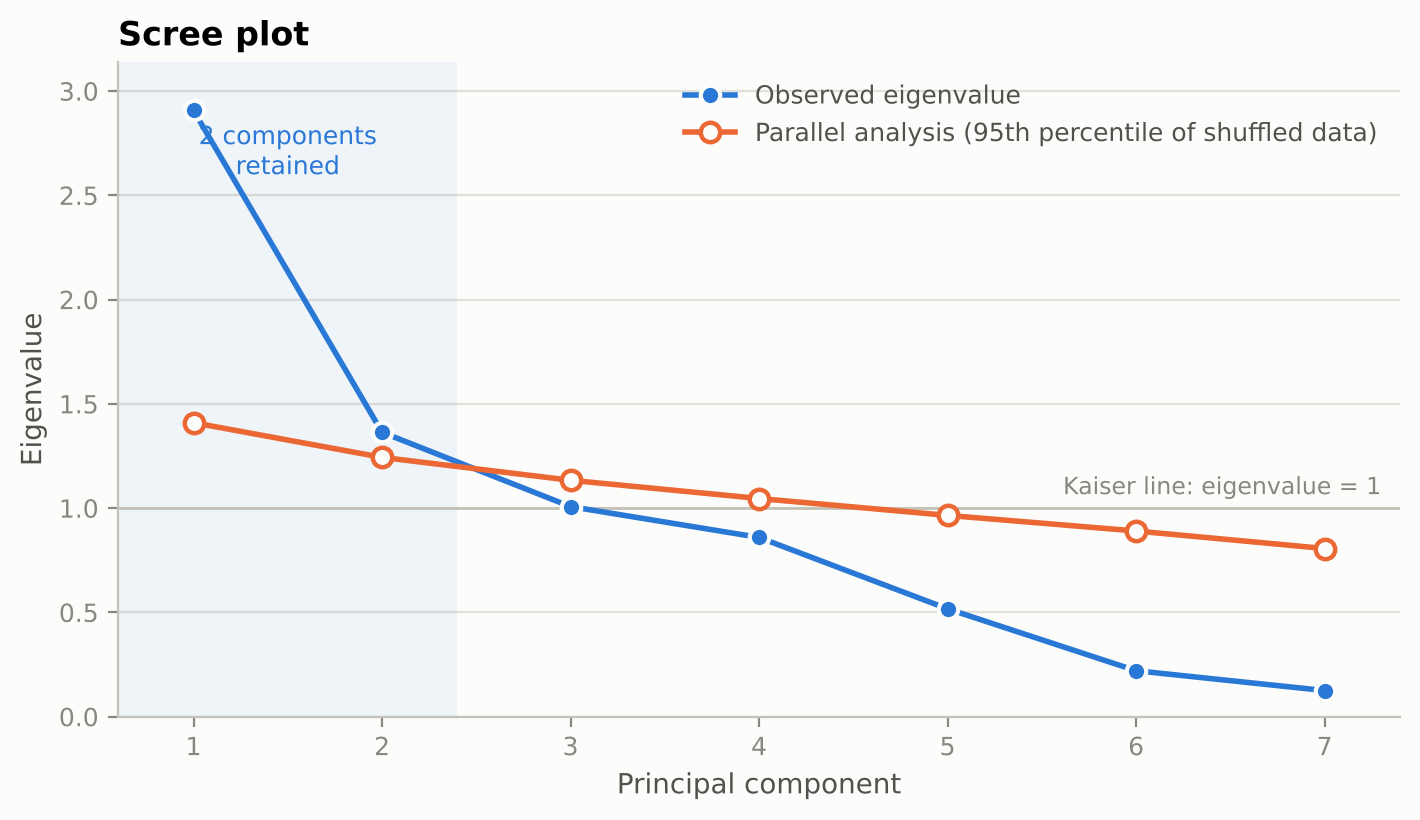

In [ ]:
# ---- Figure 1: scree plot ----
fig, ax = plt.subplots(figsize=(7.2, 4.2))
x = np.arange(1, p + 1)
ax.axhline(1, color=AXIS, linewidth=1)
ax.plot(x, eig, color=BLUE, linewidth=2, marker='o', markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5, label='Observed eigenvalue')
ax.plot(x, pa95, color=ORANGE, linewidth=2, marker='o', markersize=7, markerfacecolor=SURFACE, markeredgecolor=ORANGE, markeredgewidth=1.6,
        label='Parallel analysis (95th percentile of shuffled data)')
ax.axvspan(0.6, n_keep + 0.4, color=BLUE, alpha=0.06, linewidth=0)
ax.text(p + 0.3, 1.04, 'Kaiser line: eigenvalue = 1', color=MUTED, fontsize=8.5, va='bottom', ha='right')
ax.text((n_keep + 1) / 2, eig[0] * 0.98, f'{n_keep} components\nretained', color=BLUE, fontsize=9, ha='center', va='top')
ax.set_xticks(x); ax.set_xlim(0.6, p + 0.4); ax.set_ylim(0, eig[0] * 1.08)
ax.set_xlabel('Principal component'); ax.set_ylabel('Eigenvalue'); ax.set_title('Scree plot', loc='left', fontsize=12, fontweight='bold')
style_axes(ax, grid='y'); leg = ax.legend(frameon=False, fontsize=9, loc='upper right'); [tx.set_color(INK2) for tx in leg.get_texts()]
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig1_scree.png'); plt.show()

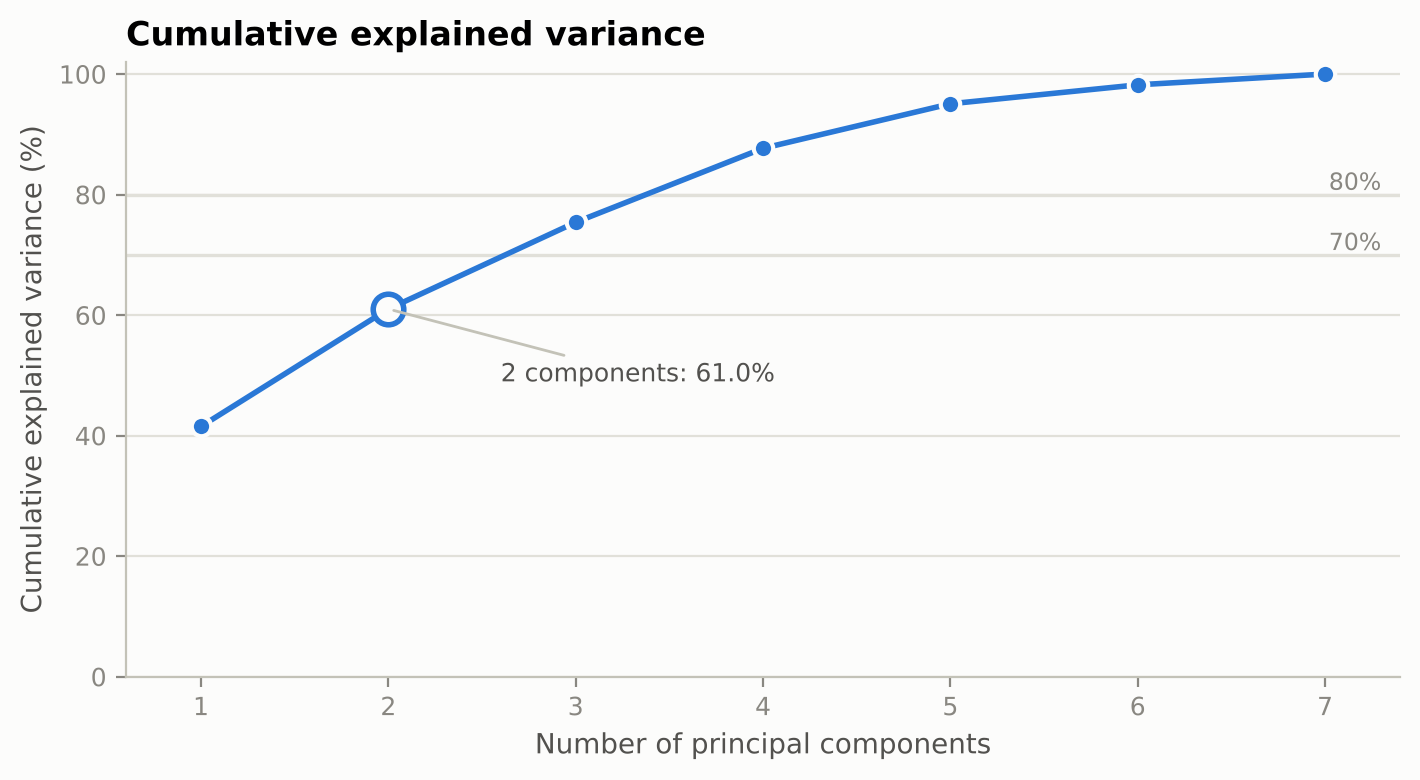

In [ ]:
# ---- Figure 2: cumulative explained variance ----
fig, ax = plt.subplots(figsize=(7.2, 4.0))
cum = ev['cumulative'].values * 100
ax.axhline(70, color=GRID, linewidth=1.2); ax.axhline(80, color=GRID, linewidth=1.2)
ax.text(p + 0.3, 70.8, '70%', color=MUTED, fontsize=8.5, ha='right'); ax.text(p + 0.3, 80.8, '80%', color=MUTED, fontsize=8.5, ha='right')
ax.plot(x, cum, color=BLUE, linewidth=2, marker='o', markersize=7, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.plot([n_keep], [cum[n_keep - 1]], marker='o', markersize=11, markerfacecolor=SURFACE, markeredgecolor=BLUE, markeredgewidth=2)
ax.annotate(f'{n_keep} components: {cum[n_keep - 1]:.1f}%', (n_keep, cum[n_keep - 1]), xytext=(n_keep + 0.6, cum[n_keep - 1] - 12),
            color=INK2, fontsize=9, arrowprops=dict(arrowstyle='-', color=AXIS))
ax.set_xticks(x); ax.set_xlim(0.6, p + 0.4); ax.set_ylim(0, 102)
ax.set_xlabel('Number of principal components'); ax.set_ylabel('Cumulative explained variance (%)')
ax.set_title('Cumulative explained variance', loc='left', fontsize=12, fontweight='bold')
style_axes(ax, grid='y'); fig.tight_layout(); fig.savefig(FIG_DIR / 'fig2_cumulative_variance.png'); plt.show()

**Choice of the number of components.** We keep the components whose eigenvalue is larger than what shuffled (structure-free)
data of the same size would give (parallel analysis). The Kaiser rule and the 70%/80% cumulative-variance rules are shown for
comparison. Reasons and trade-offs are in the interpretation at the end of the notebook.

## 8. Interpret the components

In [ ]:
pc_names = [f'PC{i + 1}' for i in range(p)]
L = pd.DataFrame(loadings, index=FEATURES_LIST, columns=pc_names)
L.round(3).to_csv(OUT_DIR / 'pca_loadings_all.csv')
Lk = L[pc_names[:n_keep]]

table = Lk.copy(); table.insert(0, 'group', [FEATURES[v][0] for v in table.index]); table.index = [LABELS[v] for v in table.index]
print('Loadings of the retained components (loading = correlation between the variable and the component):'); print(table.round(2).to_string())

for pc in Lk.columns:
    s = Lk[pc][Lk[pc].abs() >= 0.40].sort_values(key=lambda v: -v.abs())
    print(f"\n{pc} ({ev.explained_variance_ratio[int(pc[2:]) - 1]:.1%} of variance):  " + ';  '.join(f"{LABELS[i]} {v:+.2f}" for i, v in s.items()))
Lk.round(3).to_csv(OUT_DIR / 'pca_loadings_retained.csv')

Loadings of the retained components (loading = correlation between the variable and the component):
                                                 group   PC1   PC2
Evening share                                   Timing -0.12  0.81
Midnight share                                  Timing  0.31 -0.79
Weekend share                                   Timing  0.33 -0.11
All licenses per km2 (log)         Alcohol and transit  0.91  0.23
Bars and nightclubs per km2 (log)  Alcohol and transit  0.92  0.11
Dancing licenses per km2 (log)     Alcohol and transit  0.90  0.07
Metro entrances per km2 (log)      Alcohol and transit  0.46  0.03

PC1 (41.5% of variance):  Bars and nightclubs per km2 (log) +0.92;  All licenses per km2 (log) +0.91;  Dancing licenses per km2 (log) +0.90;  Metro entrances per km2 (log) +0.46

PC2 (19.5% of variance):  Evening share +0.81;  Midnight share -0.79


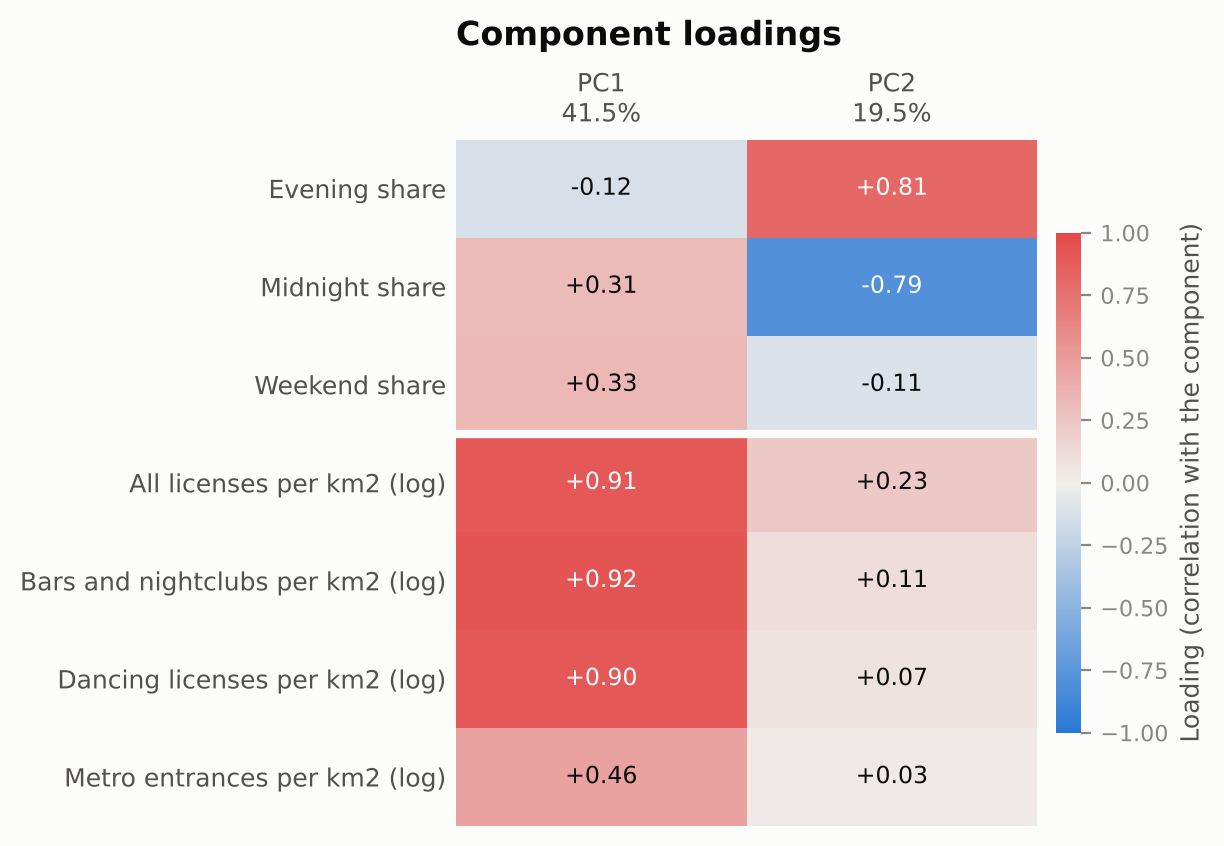

In [ ]:
# ---- Figure 3: loading heatmap of the retained components (diverging blue-red, neutral midpoint) ----
cmap = LinearSegmentedColormap.from_list('div', [BLUE, NEUTRAL, RED])
order = FEATURES_LIST
M = Lk.loc[order]
fig, ax = plt.subplots(figsize=(6.2, 4.4))
im = ax.imshow(M.values, cmap=cmap, vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(n_keep)); ax.set_xticklabels([f"{c}\n{ev.explained_variance_ratio[i]:.1%}" for i, c in enumerate(M.columns)], color=INK2, fontsize=9)
ax.set_yticks(range(len(order))); ax.set_yticklabels([LABELS[v] for v in order], color=INK2, fontsize=9)
ax.xaxis.tick_top(); ax.tick_params(length=0)
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        v = M.values[i, j]; ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=8.5, color='#ffffff' if abs(v) > 0.6 else INK)
ax.axhline(2.5, color=SURFACE, linewidth=3)        # separator between the timing and the alcohol/transit variables
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.03); cb.set_label('Loading (correlation with the component)', color=INK2, fontsize=9)
cb.ax.tick_params(colors=MUTED, labelsize=8); cb.outline.set_visible(False)
ax.set_title('Component loadings', loc='left', fontsize=12, fontweight='bold', pad=34, color=INK)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig3_loadings_heatmap.png'); plt.show()

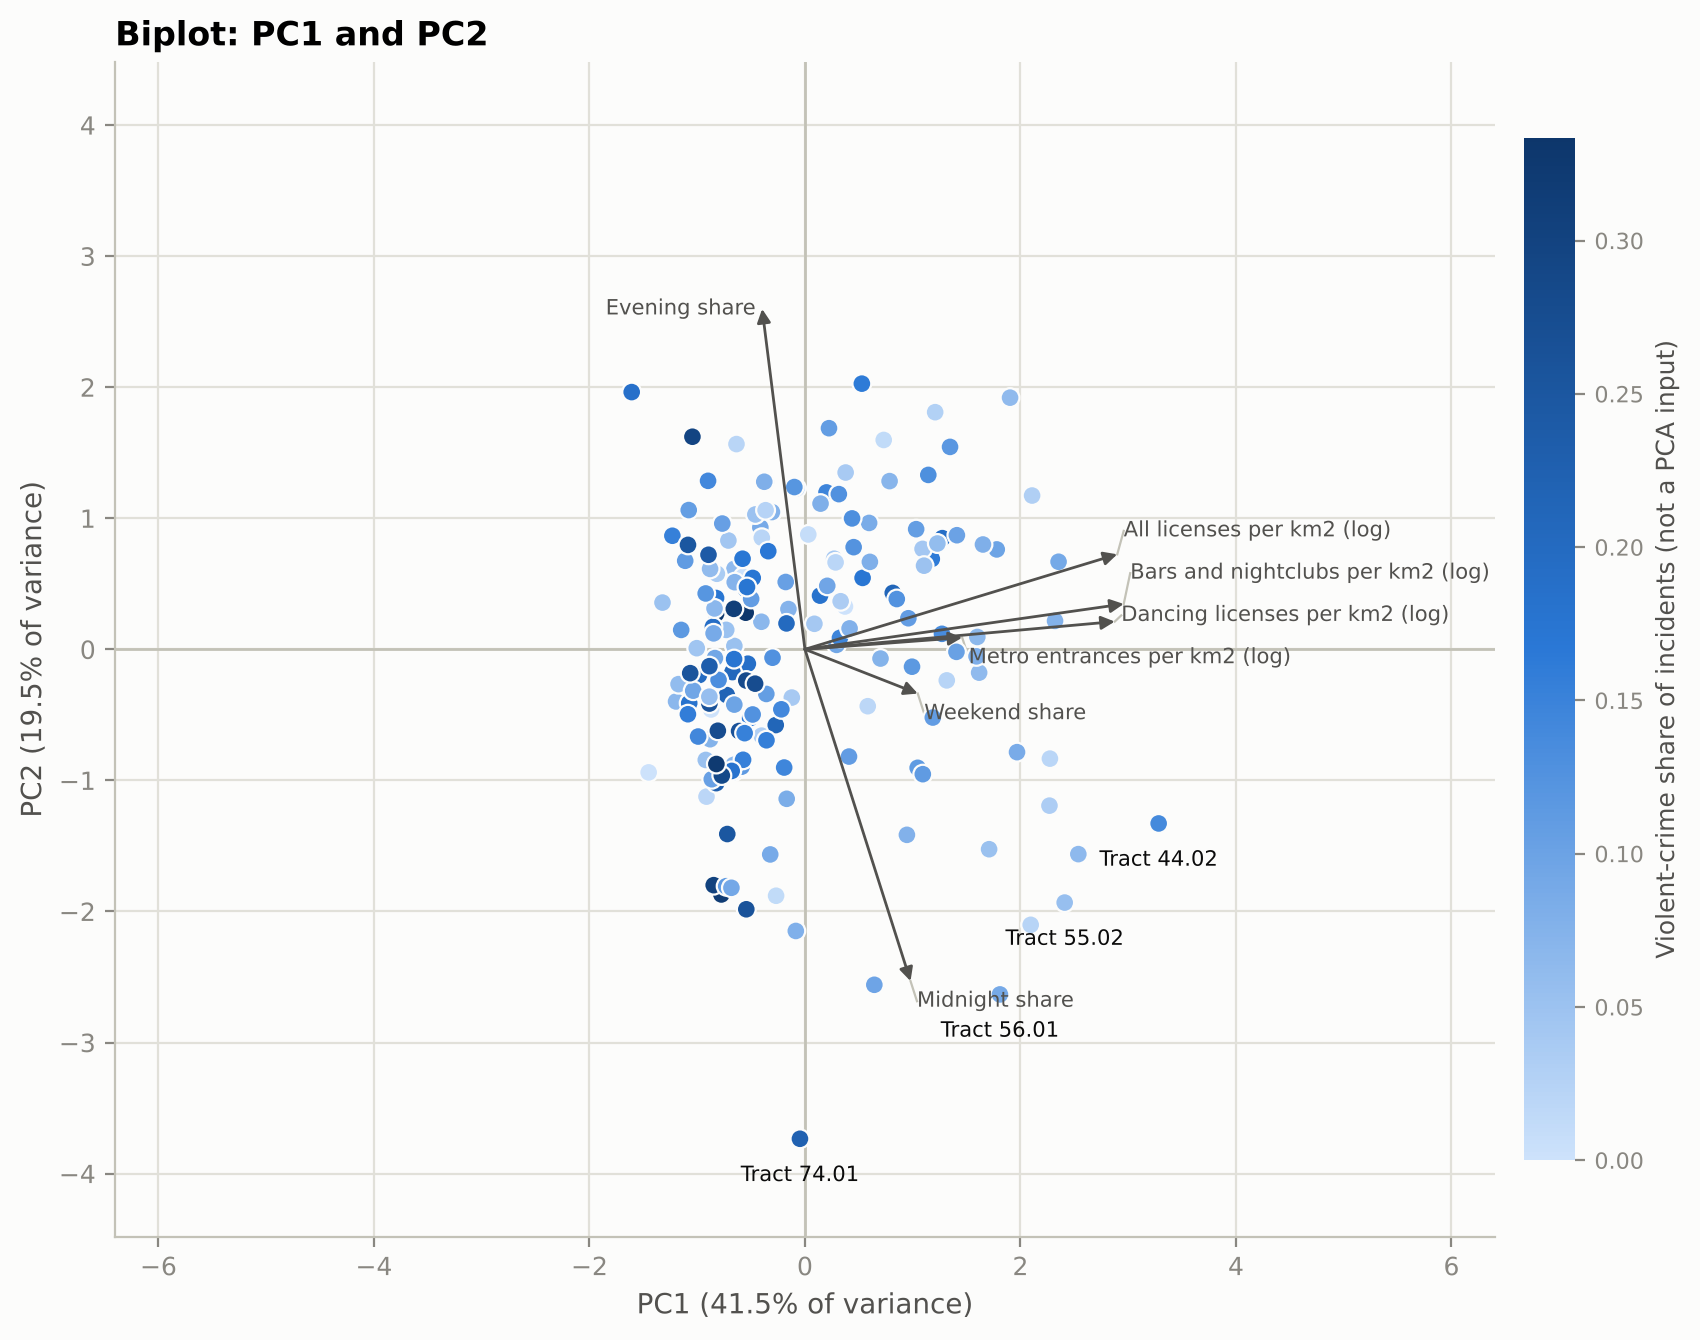

In [ ]:
# ---- Biplots (tract scores as points, loadings as arrows) ----
def spread_labels(tips, min_gap):
    # Keep arrow labels from overlapping: on each side of the vertical axis, push labels apart vertically
    pos = tips[:, 1].copy()
    for side in (tips[:, 0] >= 0, tips[:, 0] < 0):
        idx = np.where(side)[0]; idx = idx[np.argsort(pos[idx])]
        for a_, b_ in zip(idx[:-1], idx[1:]):
            if pos[b_] - pos[a_] < min_gap: pos[b_] = pos[a_] + min_gap
        if len(idx): pos[idx] -= (pos[idx] - tips[idx, 1]).mean()
    return pos

# Point color = violent-crime share of the tract's incidents. It is NOT a PCA input; it is shown as context to help reading.
color_vals = t.loc[keep, 'share_violent'].values
ARROW_MIN = 0.30

def biplot(i, j, fname, title):
    sc = scores[:, [i, j]] / np.sqrt(eig[[i, j]])                   # scores rescaled to unit variance on each axis
    ar_all = loadings[:, [i, j]] * 3.2                               # arrows: loadings, scaled up for visibility
    shown = np.hypot(loadings[:, i], loadings[:, j]) >= ARROW_MIN
    ar = ar_all[shown]; names = [v for v, s_ in zip(FEATURES_LIST, shown) if s_]
    fig, ax = plt.subplots(figsize=(8.6, 6.8))
    cmapb = LinearSegmentedColormap.from_list('seq', ['#cde2fb', '#2a78d6', '#0d366b'])
    pts = ax.scatter(sc[:, 0], sc[:, 1], c=color_vals, cmap=cmapb, s=46, edgecolor=SURFACE, linewidth=0.8, zorder=3)
    xmax = 1.95 * max(np.abs(sc[:, 0]).max(), np.abs(ar[:, 0]).max()); ymax = 1.2 * max(np.abs(sc[:, 1]).max(), np.abs(ar[:, 1]).max())
    ax.set_xlim(-xmax, xmax); ax.set_ylim(-ymax, ymax)
    ypos = spread_labels(ar, min_gap=0.036 * 2 * ymax)
    texts = []
    for v, (ax_, ay_), ly in zip(names, ar, ypos):
        ax.annotate('', xy=(ax_, ay_), xytext=(0, 0), arrowprops=dict(arrowstyle='-|>', color=INK2, lw=1.0, shrinkA=0, shrinkB=0), zorder=4)
        lx = ax_ + (0.06 if ax_ >= 0 else -0.06)
        if abs(ly - ay_) > 1e-6: ax.plot([ax_, lx], [ay_, ly], color=AXIS, linewidth=0.8, zorder=2)
        texts.append(ax.text(lx, ly, LABELS[v], fontsize=7.6, color=INK2, ha='left' if ax_ >= 0 else 'right', va='center', zorder=5))
    ax.axhline(0, color=AXIS, linewidth=1); ax.axvline(0, color=AXIS, linewidth=1)
    ax.set_xlabel(f'PC{i + 1} ({ev.explained_variance_ratio[i]:.1%} of variance)'); ax.set_ylabel(f'PC{j + 1} ({ev.explained_variance_ratio[j]:.1%} of variance)')
    ax.set_title(title, loc='left', fontsize=12, fontweight='bold')
    style_axes(ax)
    cb = fig.colorbar(pts, ax=ax, fraction=0.035, pad=0.02); cb.set_label('Violent-crime share of incidents (not a PCA input)', color=INK2, fontsize=9)
    cb.ax.tick_params(colors=MUTED, labelsize=8); cb.outline.set_visible(False)
    fig.tight_layout(); fig.canvas.draw(); rend = fig.canvas.get_renderer()
    # label the four tracts farthest from the center, choosing a side of the point that does not collide with other labels
    placed = [t_.get_window_extent(rend) for t_ in texts]
    for f in np.argsort(-np.hypot(sc[:, 0], sc[:, 1]))[:4]:
        name = analysis.loc[f, 'NAME'].replace('Census Tract ', 'Tract ')
        for dx, dy, ha, va in [(0, -0.2, 'center', 'top'), (0, 0.2, 'center', 'bottom'), (0.15, 0, 'left', 'center'), (-0.15, 0, 'right', 'center')]:
            tx = ax.text(sc[f, 0] + dx, sc[f, 1] + dy, name, fontsize=7.6, color=INK, ha=ha, va=va, zorder=6)
            bb = tx.get_window_extent(rend)
            if any(bb.overlaps(o) for o in placed): tx.remove(); continue
            placed.append(bb); break
    fig.savefig(FIG_DIR / fname); plt.show()

biplot(0, 1, 'fig4_biplot_pc1_pc2.png', 'Biplot: PC1 and PC2')
if n_keep >= 4:   biplot(2, 3, 'fig5_biplot_pc3_pc4.png', 'Biplot: PC3 and PC4')
elif n_keep == 3: biplot(0, 2, 'fig5_biplot_pc1_pc3.png', 'Biplot: PC1 and PC3')

**Reading the biplots.** Each point is a tract; each arrow shows how a variable points through the plane (arrow length is the
variable's loading, scaled up for visibility). Point color is the violent-crime share, which is **not** a PCA input and is only
shown to help interpretation. PCA shows directions of variation, **not clusters**. Apparent groups of points in these plots
are not confirmed clusters.

## 9. Context variables (not PCA inputs)

The violent-crime share and the ACS resident variables were held out of the PCA. Correlating them with the retained component
scores shows what each component *goes with*, without those variables having shaped the components. Spearman (rank) correlations
are used because several of these variables are skewed. The same variables are the planned predictors for the classification stage.

In [ ]:
ctx_cols = {'share_violent': 'Violent-crime share', 'share_gun': 'Gun-involved share', 'incidents_per_1000_residents': 'Incidents per 1,000 residents',
            'median_age': 'Median age', 'poverty_rate': 'Poverty rate', 'renter_share': 'Renter share',
            'transit_commute_share': 'Transit commute share', 'population_density_per_sq_mile': 'Population density',
            'median_household_income_2024usd': 'Median household income'}
ctx = t.loc[keep, list(ctx_cols)].reset_index(drop=True)
S = pd.DataFrame(scores[:, :n_keep], columns=pc_names[:n_keep])
ctx_corr = pd.DataFrame({pc: ctx.apply(lambda col: col.corr(S[pc], method='spearman')) for pc in S.columns}).rename(index=ctx_cols)
ctx_corr['n_missing'] = ctx.isna().sum().values
print('Spearman correlation of context variables with the retained component scores:'); print(ctx_corr.round(2).to_string())
ctx_corr.round(3).to_csv(OUT_DIR / 'context_correlations.csv')

Spearman correlation of context variables with the retained component scores:
                                PC1   PC2  n_missing
Violent-crime share           -0.29 -0.14          0
Gun-involved share            -0.38 -0.21          0
Incidents per 1,000 residents  0.39  0.15          0
Median age                    -0.14  0.08          1
Poverty rate                  -0.25 -0.22          0
Renter share                   0.12 -0.00          1
Transit commute share         -0.15 -0.04          0
Population density             0.42  0.19          0
Median household income        0.32  0.23          8


## 10. Sensitivity checks

In [ ]:
# Does the structure change when we change the tract filter or the variable set?  Tucker congruence compares loading patterns
# on the variables the two analyses share (1.0 = identical; sign flips are ignored).
def fit(mask, feats):
    d = t.loc[mask, feats].dropna()
    z = (d - d.mean()) / d.std(ddof=1)
    pc = PCA(svd_solver='full').fit(z)
    cp = pc.components_.copy()
    for i in range(len(cp)):
        if cp[i, np.argmax(np.abs(cp[i]))] < 0: cp[i] *= -1
    return len(d), pc.explained_variance_ratio_, pd.DataFrame(cp.T * np.sqrt(pc.explained_variance_), index=feats)
def tucker(a, b): return abs(a @ b) / np.sqrt((a @ a) * (b @ b))

base_mask = t['timing_n'] >= MIN_TIMING_N
variants = {
    'Main analysis':                           (base_mask, FEATURES_LIST),
    'Tract minimum 20 incidents':              (t['timing_n'] >= 20, FEATURES_LIST),
    'Tract minimum 50 incidents':              (t['timing_n'] >= 50, FEATURES_LIST),
    'Without the tracts flagged as outliers':  (base_mask & ~t['GEOID'].isin(outlier_geoids), FEATURES_LIST),
    'Without dancing-license density':         (base_mask, [v for v in FEATURES_LIST if v != 'log_dancing_per_km2']),
    'Timing shares only (3 variables)':        (base_mask, ['share_evening', 'share_midnight', 'share_weekend']),
}
_, evr0, L0 = fit(*variants['Main analysis'])
rows = []
for name, (m, f) in variants.items():
    n_, evr, Lv = fit(m, f)
    common = [v for v in FEATURES_LIST if v in f]
    k_ = min(3, Lv.shape[1])
    rows.append([name, n_, len(f)] + [round(float(evr[i]), 3) if i < len(evr) else np.nan for i in range(3)]
                + [round(float(tucker(L0.loc[common].iloc[:, i].values, Lv.loc[common].iloc[:, i].values)), 2) if i < k_ else np.nan for i in range(3)])
sens = pd.DataFrame(rows, columns=['variant', 'tracts', 'variables', 'EVR PC1', 'EVR PC2', 'EVR PC3', 'match PC1', 'match PC2', 'match PC3'])
sens.to_csv(OUT_DIR / 'sensitivity.csv', index=False)
sens

,variant,tracts,variables,EVR PC1,EVR PC2,EVR PC3,match PC1,match PC2,match PC3
0,Main analysis,174,7,0.415,0.195,0.144,1.00,1.00,1.00
1,Tract minimum 20 incidents,184,7,0.413,0.192,0.143,1.00,1.00,1.00
2,Tract minimum 50 incidents,132,7,0.418,0.207,0.131,1.00,0.97,0.96
3,Without the tracts flagged as outliers,173,7,0.414,0.200,0.140,1.00,1.00,0.99
4,Without dancing-license density,174,6,0.363,0.226,0.168,1.00,1.00,1.00
5,Timing shares only (3 variables),174,3,0.474,0.353,0.173,0.83,0.19,0.00


## 11. Save results for the clustering stage

In [ ]:
keep_pcs = pc_names[:n_keep]
out_scores = pd.concat([analysis[['GEOID', 'NAME']], pd.DataFrame(scores[:, :n_keep], columns=keep_pcs)], axis=1)
out_scores.round(4).to_csv(OUT_DIR / 'pca_scores_retained.csv', index=False)
analysis.round(4).to_csv(OUT_DIR / 'pca_input_variables.csv', index=False)
t.loc[keep, ['GEOID', 'NAME'] + list(ctx_cols)].round(4).to_csv(OUT_DIR / 'pca_context_variables.csv', index=False)
print('Saved:', *sorted(p_.name for p_ in list(OUT_DIR.glob('*.csv')) + list(FIG_DIR.glob('*.png'))), sep='\n  ')
out_scores.head()

Saved:
  context_correlations.csv
  explained_variance.csv
  fig1_scree.png
  fig2_cumulative_variance.png
  fig3_loadings_heatmap.png
  fig4_biplot_pc1_pc2.png
  pca_context_variables.csv
  pca_excluded_tracts.csv
  pca_input_variables.csv
  pca_loadings_all.csv
  pca_loadings_retained.csv
  pca_scores_retained.csv
  sensitivity.csv


,GEOID,NAME,PC1,PC2
0,11001002002,Census Tract 20.02,-1.532714,1.501407
1,11001002101,Census Tract 21.01,1.694306,-0.154870
2,11001002102,Census Tract 21.02,-0.705550,1.086120
3,11001002201,Census Tract 22.01,0.500563,0.039670
4,11001002202,Census Tract 22.02,-1.144633,-1.097072
